In [1]:
import pandas as pd
from camp2ascii import camp2ascii as c2a
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [2]:
download_date = "2026_10_07"

Load data

In [ ]:
data_dir = Path("L0a_raw") / f"{download_date}" / "data"

fast_files = list(data_dir.glob("*Fast*"))
slow_raw_files = list(data_dir.glob("*SlowRaw*"))
slow_stats_files = list(data_dir.glob("*SlowStats*"))

slow_raw_df = pd.concat(c2a(slow_raw_files, Path("/tmp"), output_format=4, n_invalid=10, pbar=True, verbose=0))
slow_raw_df = slow_raw_df.set_index("TIMESTAMP").sort_index()

slow_stats_df = pd.concat(c2a(slow_stats_files, Path("/tmp"), output_format=4, n_invalid=10, pbar=True, verbose=0))
slow_stats_df = slow_stats_df.set_index("TIMESTAMP").sort_index()

# # Too slow to do here
# fast_df = pd.concat(c2a(fast_files, Path("/tmp"), output_format=4, n_invalid=10, pbar=True, verbose=0))
# fast_df = fast_df.set_index("TIMESTAMP").sort_index()

Processing files: 100%|██████████| 2.83M/2.83M [00:00<00:00, 11.8MB/s]
Processing files: 100%|██████████| 1.11M/1.11M [00:00<00:00, 24.1MB/s]


Plot data

Text(2026-09-03 08:50:00, 12.01, 'Danger!')

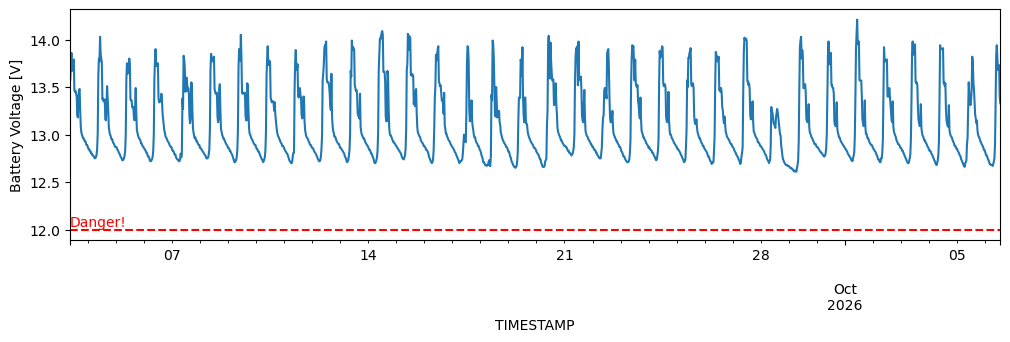

In [71]:
slow_stats_df["batt_Min"].plot(figsize=(12,3), ylabel="Battery Voltage [V]");
plt.axhline(y=12.0, color='r', linestyle='--')
plt.text(x=slow_raw_df.index[0], y=12.01, s="Danger!", color='r', fontsize=10, verticalalignment='bottom')

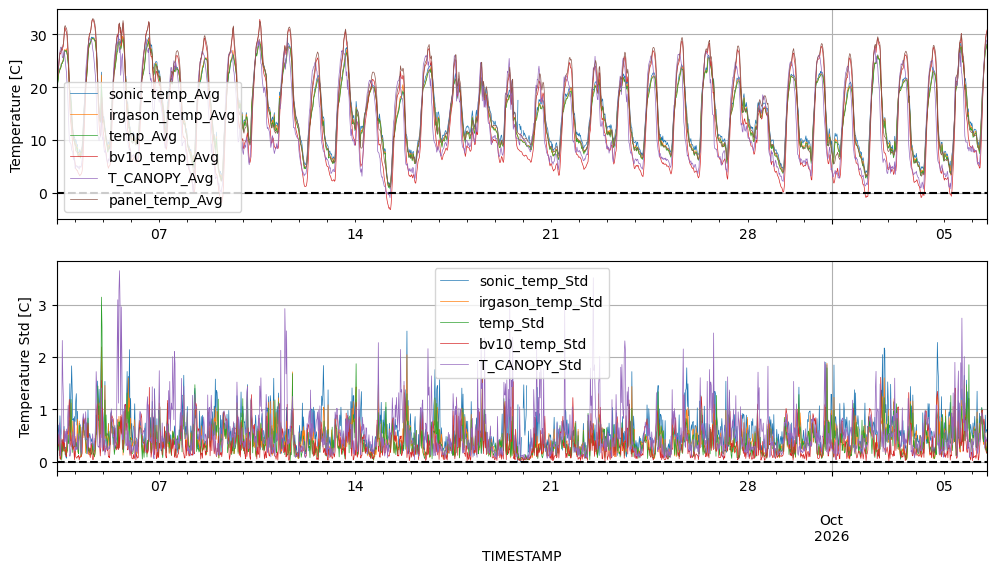

In [115]:
fig, axs = plt.subplots(figsize=(12,6), nrows=2)
slow_stats_df[["sonic_temp_Avg", "irgason_temp_Avg", "temp_Avg", "bv10_temp_Avg", "T_CANOPY_Avg", "panel_temp_Avg"]].plot(ylabel="Temperature [C]", ax=axs[0], lw=0.5);
slow_stats_df[["sonic_temp_Std", "irgason_temp_Std", "temp_Std", "bv10_temp_Std", "T_CANOPY_Std"]].plot(ylabel="Temperature Std [C]", ax=axs[1], lw=0.5);
axs[0].axhline(y=0, color='k', linestyle='--');
axs[1].axhline(y=0, color='k', linestyle='--');
for ax in axs:
    ax.grid(True);

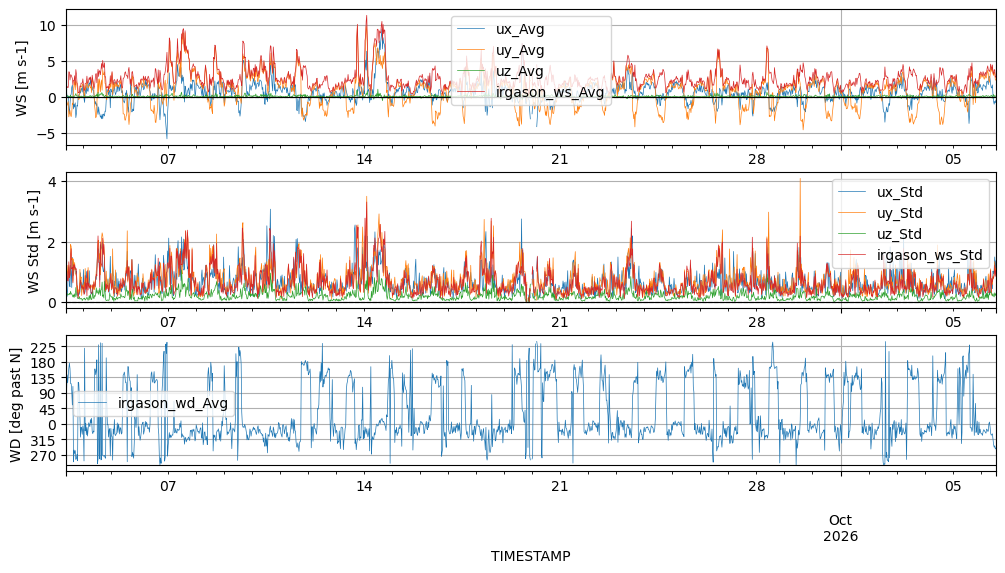

In [ ]:
fig, axs = plt.subplots(figsize=(12,6), nrows=3)
slow_stats_df[["ux_Avg", "uy_Avg", "uz_Avg", "irgason_ws_Avg"]].plot(ylabel="WS [m s-1]", ax=axs[0], lw=0.5);
slow_stats_df[["ux_Std", "uy_Std", "uz_Std", "irgason_ws_Std"]].plot(ylabel="WS Std [m s-1]", ax=axs[1], lw=0.5);
((slow_stats_df[["irgason_wd_Avg"]] - 120) % 360).plot(ylabel="WD [deg past N]", ax=axs[2], lw=0.5);
wds = np.arange(120, 360+120, 45) % 360
wd_new = wds - 120
axs[2].set_yticks(wds, wd_new%360)
axs[0].axhline(y=0, color='k', linestyle='--', lw=0.8);
axs[1].axhline(y=0, color='k', linestyle='--', lw=0.8);
for ax in axs:
    ax.grid(True)

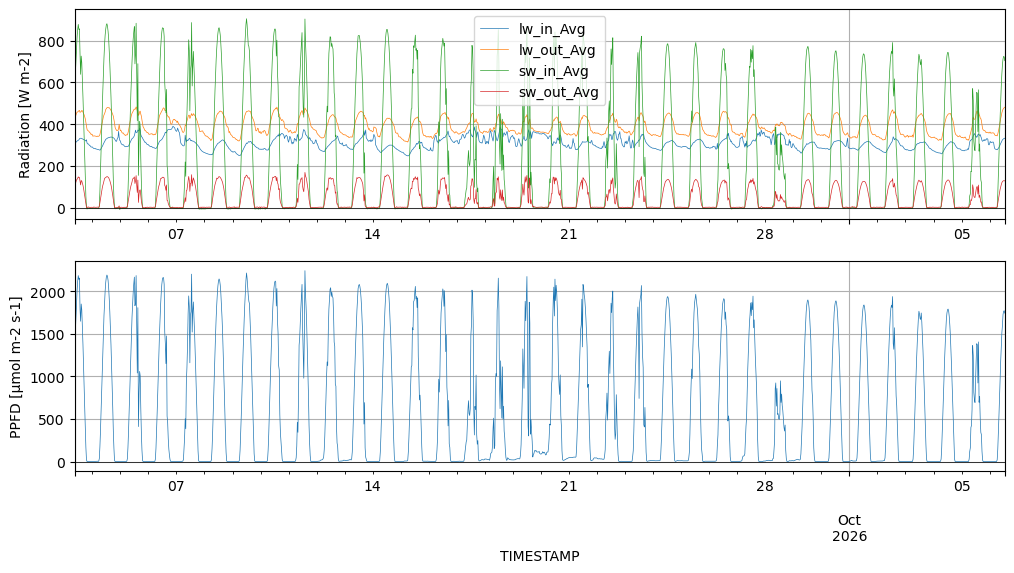

In [111]:
fig, axs = plt.subplots(figsize=(12,6), nrows=2)
slow_stats_df[["lw_in_Avg", "lw_out_Avg", "sw_in_Avg", "sw_out_Avg"]].plot(lw=0.5, ylabel="Radiation [W m-2]", ax=axs[0]);
slow_stats_df["ppfd_Avg"].plot(lw=0.5, ylabel="PPFD [µmol m-2 s-1]", ax=axs[1]);
for ax in axs:
    ax.grid(True)
    ax.axhline(0, color='k', lw=0.5)

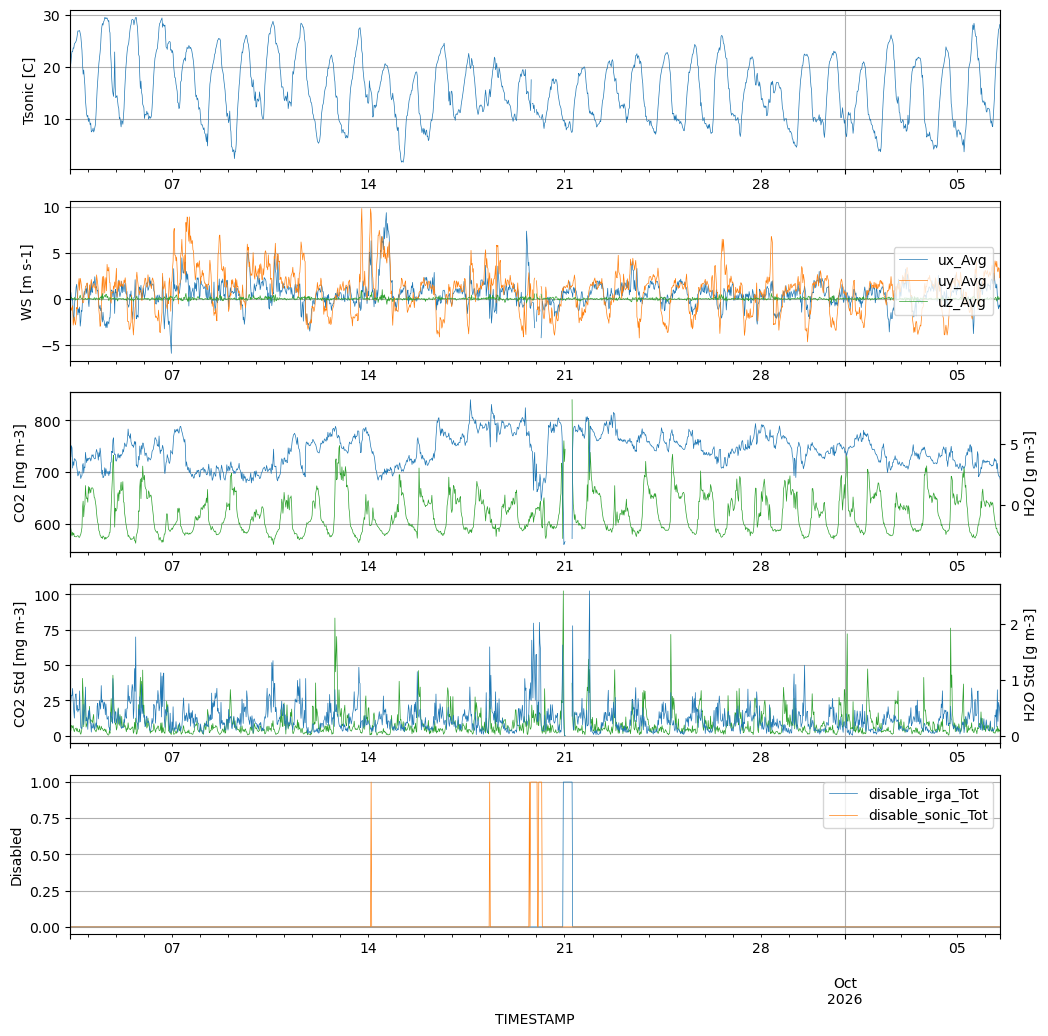

In [114]:
fig, axs = plt.subplots(figsize=(12,12), nrows=5)

# plot a twin-axis plot, sonic_temp on left, disable_sonic_Tot on right
slow_stats_df["sonic_temp_Avg"].plot(ylabel="Tsonic [C]", ax=axs[0], lw=0.5);

slow_stats_df[["ux_Avg", "uy_Avg", "uz_Avg"]].plot(ylabel="WS [m s-1]", ax=axs[1], lw=0.5);
axs[1].legend(loc="center right")

ax2_twin = axs[2].twinx()
slow_stats_df["rho_co2_Avg"].plot(ylabel="CO2 [mg m-3]", ax=axs[2], lw=0.5, color="C2");
slow_stats_df["rho_h2o_Avg"].plot(ylabel="H2O [g m-3]", ax=ax2_twin, lw=0.5);

ax3_twin = axs[3].twinx()
slow_stats_df["rho_co2_Std"].plot(ylabel="CO2 Std [mg m-3]", ax=axs[3], lw=0.5, color="C2");
slow_stats_df["rho_h2o_Std"].plot(ylabel="H2O Std [g m-3]", ax=ax3_twin, lw=0.5);

((slow_stats_df[["disable_irga_Tot", "disable_sonic_Tot"]] > 180*20)*1).plot(ylabel="Disabled", ax=axs[4], lw=0.5);

for ax in axs:
    ax.grid(True)

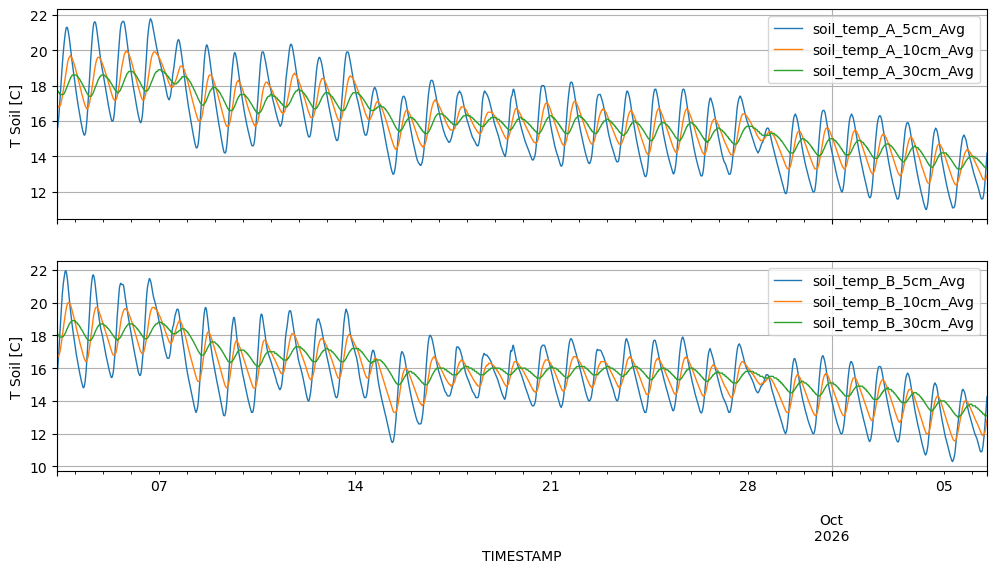

In [127]:
fig, axs = plt.subplots(figsize=(12,6), nrows=2, sharex="all")
slow_stats_df.filter(regex="soil_temp_A_.*_Avg").plot(lw=1.0, ax=axs[0], ylabel="T Soil [C]")
slow_stats_df.filter(regex="soil_temp_B_.*_Avg").plot(lw=1.0, ax=axs[1], ylabel="T Soil [C]")
for ax in axs:
    ax.grid(True)

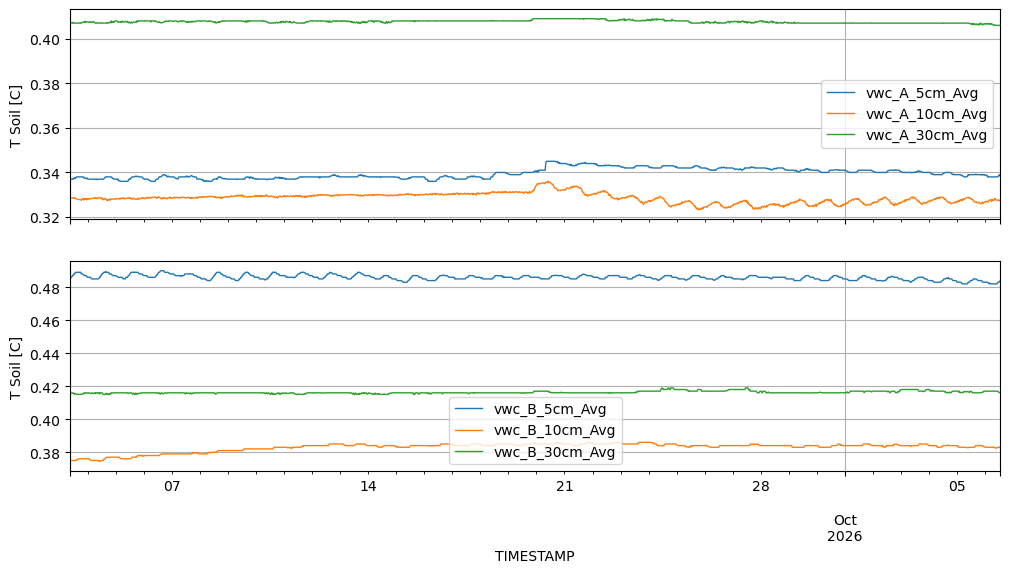

In [129]:
fig, axs = plt.subplots(figsize=(12,6), nrows=2, sharex="all")
slow_stats_df.filter(regex="vwc_A_.*_Avg").plot(lw=1.0, ax=axs[0], ylabel="T Soil [C]")
slow_stats_df.filter(regex="vwc_B_.*_Avg").plot(lw=1.0, ax=axs[1], ylabel="T Soil [C]")
for ax in axs:
    ax.grid(True)

<Axes: xlabel='TIMESTAMP', ylabel='G [W m-2]'>

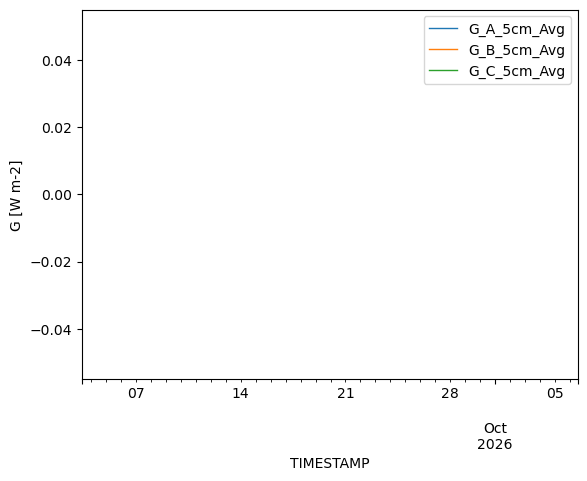

In [128]:
slow_stats_df.filter(regex="G_.*_Avg").plot(lw=1.0, ylabel="G [W m-2]")